> Adapted from *Dive into Deep Learning*, section [Padding and Stride](https://d2l.ai/chapter_convolutional-neural-networks/padding-and-strides.html). Not affiliated with or endorsed by the book's authors.
> Source, authors, licenses and changes: [Attribution and changes](#Attribution-and-changes), at the end of this notebook.

# Padding and Stride

Recall the example of a convolution in [Fig. 7.2.1](https://d2l.ai/chapter_convolutional-neural-networks/conv-layer.html#fig-correlation). 
The input had both a height and width of 3
and the convolution kernel had both a height and width of 2,
yielding an output representation with dimension $2\times2$.
Assuming that the input shape is $n_\textrm{h}\times n_\textrm{w}$
and the convolution kernel shape is $k_\textrm{h}\times k_\textrm{w}$,
the output shape will be $(n_\textrm{h}-k_\textrm{h}+1) \times (n_\textrm{w}-k_\textrm{w}+1)$: 
we can only shift the convolution kernel so far until it runs out
of pixels to apply the convolution to. 

In the following we will explore a number of techniques, 
including padding and strided convolutions,
that offer more control over the size of the output. 
As motivation, note that since kernels generally
have width and height greater than $1$,
after applying many successive convolutions,
we tend to wind up with outputs that are
considerably smaller than our input.
If we start with a $240 \times 240$ pixel image,
ten layers of $5 \times 5$ convolutions
reduce the image to $200 \times 200$ pixels,
slicing off $30 \%$ of the image and with it
obliterating any interesting information
on the boundaries of the original image.
*Padding* is the most popular tool for handling this issue.
In other cases, we may want to reduce the dimensionality drastically,
e.g., if we find the original input resolution to be unwieldy.
*Strided convolutions* are a popular technique that can help in these instances.

In [ ]:
import numpy as np
from divelet_ml import nn

import divelet_ml as d2l

## Padding

As described above, one tricky issue when applying convolutional layers
is that we tend to lose pixels on the perimeter of our image. Consider the figure below that depicts the pixel utilization as a function of the convolution kernel size and the position within the image. The pixels in the corners are hardly used at all. 

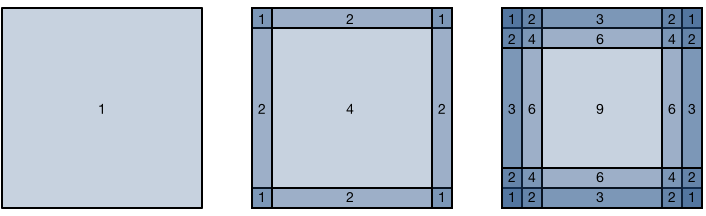

Since we typically use small kernels,
for any given convolution
we might only lose a few pixels
but this can add up as we apply
many successive convolutional layers.
One straightforward solution to this problem
is to add extra pixels of filler around the boundary of our input image,
thus increasing the effective size of the image.
Typically, we set the values of the extra pixels to zero.
In the figure below, we pad a $3 \times 3$ input,
increasing its size to $5 \times 5$.
The corresponding output then increases to a $4 \times 4$ matrix.
The shaded portions are the first output element as well as the input and kernel tensor elements used for the output computation: $0\times0+0\times1+0\times2+0\times3=0$.

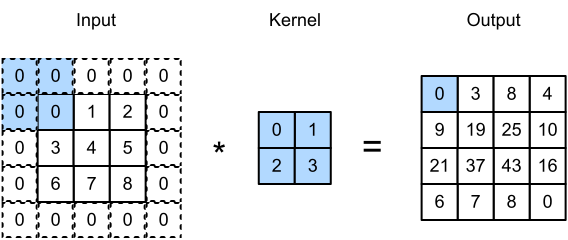

In general, if we add a total of $p_\textrm{h}$ rows of padding
(roughly half on top and half on bottom)
and a total of $p_\textrm{w}$ columns of padding
(roughly half on the left and half on the right),
the output shape will be

$$(n_\textrm{h}-k_\textrm{h}+p_\textrm{h}+1)\times(n_\textrm{w}-k_\textrm{w}+p_\textrm{w}+1).$$

This means that the height and width of the output
will increase by $p_\textrm{h}$ and $p_\textrm{w}$, respectively.

In many cases, we will want to set $p_\textrm{h}=k_\textrm{h}-1$ and $p_\textrm{w}=k_\textrm{w}-1$
to give the input and output the same height and width.
This will make it easier to predict the output shape of each layer
when constructing the network.
Assuming that $k_\textrm{h}$ is odd here,
we will pad $p_\textrm{h}/2$ rows on both sides of the height.
If $k_\textrm{h}$ is even, one possibility is to
pad $\lceil p_\textrm{h}/2\rceil$ rows on the top of the input
and $\lfloor p_\textrm{h}/2\rfloor$ rows on the bottom.
We will pad both sides of the width in the same way.

CNNs commonly use convolution kernels
with odd height and width values, such as 1, 3, 5, or 7.
Choosing odd kernel sizes has the benefit
that we can preserve the dimensionality
while padding with the same number of rows on top and bottom,
and the same number of columns on left and right.

Moreover, this practice of using odd kernels
and padding to precisely preserve dimensionality
offers a clerical benefit.
For any two-dimensional tensor `X`,
when the kernel's size is odd
and the number of padding rows and columns
on all sides are the same,
thereby producing an output with the same height and width as the input,
we know that the output `Y[i, j]` is calculated
by cross-correlation of the input and convolution kernel
with the window centered on `X[i, j]`.

In the following example, we create a two-dimensional convolutional layer
with a height and width of 3
and apply 1 pixel of padding on all sides.
Given an input with a height and width of 8,
we find that the height and width of the output is also 8.

In [ ]:
# We define a helper function to calculate convolutions. It initializes the
# convolutional layer weights and performs corresponding dimensionality
# elevations and reductions on the input and output
def comp_conv2d(conv2d, X):
    # (1, 1) indicates that batch size and the number of channels are both 1
    X = X.reshape((1, 1) + X.shape)
    Y = conv2d(X)
    # Strip the first two dimensions: examples and channels
    return Y.reshape(Y.shape[2:])

# 1 row and column is padded on either side, so a total of 2 rows or columns
# are added
conv2d = nn.LazyConv2d(1, kernel_size=3, padding=1)
X = np.random.rand(8, 8)
comp_conv2d(conv2d, X).shape

When the height and width of the convolution kernel are different,
we can make the output and input have the same height and width
by setting different padding numbers for height and width.

In [ ]:
# We use a convolution kernel with height 5 and width 3. The padding on either
# side of the height and width are 2 and 1, respectively
conv2d = nn.LazyConv2d(1, kernel_size=(5, 3), padding=(2, 1))
comp_conv2d(conv2d, X).shape

## Stride

When computing the cross-correlation,
we start with the convolution window
at the upper-left corner of the input tensor,
and then slide it over all locations both down and to the right.
In the previous examples, we defaulted to sliding one element at a time.
However, sometimes, either for computational efficiency
or because we wish to downsample,
we move our window more than one element at a time,
skipping the intermediate locations. This is particularly useful if the convolution 
kernel is large since it captures a large area of the underlying image.

We refer to the number of rows and columns traversed per slide as *stride*.
So far, we have used strides of 1, both for height and width.
Sometimes, we may want to use a larger stride.
the figure below shows a two-dimensional cross-correlation operation
with a stride of 3 vertically and 2 horizontally.
The shaded portions are the output elements as well as the input and kernel tensor elements used for the output computation: $0\times0+0\times1+1\times2+2\times3=8$, $0\times0+6\times1+0\times2+0\times3=6$.
We can see that when the second element of the first column is generated,
the convolution window slides down three rows.
The convolution window slides two columns to the right
when the second element of the first row is generated.
When the convolution window continues to slide two columns to the right on the input,
there is no output because the input element cannot fill the window
(unless we add another column of padding).

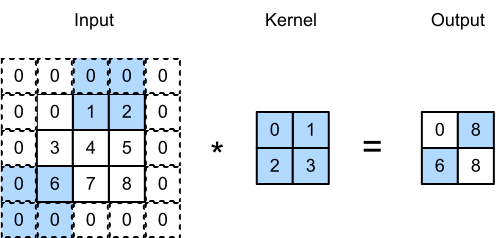

In general, when the stride for the height is $s_\textrm{h}$
and the stride for the width is $s_\textrm{w}$, the output shape is

$$\lfloor(n_\textrm{h}-k_\textrm{h}+p_\textrm{h}+s_\textrm{h})/s_\textrm{h}\rfloor \times \lfloor(n_\textrm{w}-k_\textrm{w}+p_\textrm{w}+s_\textrm{w})/s_\textrm{w}\rfloor.$$

If we set $p_\textrm{h}=k_\textrm{h}-1$ and $p_\textrm{w}=k_\textrm{w}-1$,
then the output shape can be simplified to
$\lfloor(n_\textrm{h}+s_\textrm{h}-1)/s_\textrm{h}\rfloor \times \lfloor(n_\textrm{w}+s_\textrm{w}-1)/s_\textrm{w}\rfloor$.
Going a step further, if the input height and width
are divisible by the strides on the height and width,
then the output shape will be $(n_\textrm{h}/s_\textrm{h}) \times (n_\textrm{w}/s_\textrm{w})$.

Below, we set the strides on both the height and width to 2,
thus halving the input height and width.

In [ ]:
conv2d = nn.LazyConv2d(1, kernel_size=3, padding=1, stride=2)
comp_conv2d(conv2d, X).shape

Let's look at a slightly more complicated example.

In [ ]:
conv2d = nn.LazyConv2d(1, kernel_size=(3, 5), padding=(0, 1), stride=(3, 4))
comp_conv2d(conv2d, X).shape

## Summary and Discussion

Padding can increase the height and width of the output. This is often used to give the output the same height and width as the input to avoid undesirable shrinkage of the output. Moreover, it ensures that all pixels are used equally frequently. Typically we pick symmetric padding on both sides of the input height and width. In this case we refer to $(p_\textrm{h}, p_\textrm{w})$ padding. Most commonly we set $p_\textrm{h} = p_\textrm{w}$, in which case we simply state that we choose padding $p$. 

A similar convention applies to strides. When horizontal stride $s_\textrm{h}$ and vertical stride $s_\textrm{w}$ match, we simply talk about stride $s$. The stride can reduce the resolution of the output, for example reducing the height and width of the output to only $1/n$ of the height and width of the input for $n > 1$. By default, the padding is 0 and the stride is 1. 

So far all padding that we discussed simply extended images with zeros. This has significant computational benefit since it is trivial to accomplish. Moreover, operators can be engineered to take advantage of this padding implicitly without the need to allocate additional memory. At the same time, it allows CNNs to encode implicit position information within an image, simply by learning where the "whitespace" is. There are many alternatives to zero-padding. Alsallakh et al. (2020) provided an extensive overview of those (albeit without a clear case for when to use nonzero paddings unless artifacts occur). 


## Exercises

1. Given the final code example in this section with kernel size $(3, 5)$, padding $(0, 1)$, and stride $(3, 4)$, 
   calculate the output shape to check if it is consistent with the experimental result.
1. For audio signals, what does a stride of 2 correspond to?
1. Implement mirror padding, i.e., padding where the border values are simply mirrored to extend tensors. 
1. What are the computational benefits of a stride larger than 1?
1. What might be statistical benefits of a stride larger than 1?
1. How would you implement a stride of $\frac{1}{2}$? What does it correspond to? When would this be useful?



Discussions of the original section: [book's forum](https://discuss.d2l.ai/t/68)

## Attribution and changes

Adapted from *Dive into Deep Learning*, section
[Padding and Stride](https://d2l.ai/chapter_convolutional-neural-networks/padding-and-strides.html)
(source: [`chapter_convolutional-neural-networks/padding-and-strides.md`](https://github.com/d2l-ai/d2l-en/blob/23d7a5aecceee57d1292c56e90cce307f183bb0a/chapter_convolutional-neural-networks/padding-and-strides.md)
at commit `23d7a5aeccee`), by Aston Zhang, Zachary C. Lipton, Mu Li, Alexander J. Smola and contributors.
Text and figures: [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/). Code: adapted from the book's sample code, MIT-0.
Not affiliated with or endorsed by the book's authors.

**Changes from the original** (PyTorch edition):
- Code uses NumPy instead of PyTorch, so it runs in JupyterLite (Pyodide and xeus-python). The word *tensor* is kept and means a NumPy `ndarray`.
- `d2l` is divelet-ml's package (`import divelet_ml as d2l`) instead of the book's `d2l.torch`.
- `nn.LazyConv2d` is divelet-ml's, with the `padding` and `stride` arguments of PyTorch's; `torch.rand` is `np.random.rand`.
- The figures are embedded in the notebook as PNG data URIs, rendered from the book's image files, so the notebook loads no other file; references to them say "the figure above" or "the figure below".
- Cross-references to other sections link to the book's site, and citations are written inline (author and year); the book's bibliography lists them.
- The d2lbook framework tabs for MXNet, TensorFlow and JAX are removed.